# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [4]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [5]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0             67            154  0.734583
1       1             -5              6  0.684094
2       2             61            126  0.815257
3       3             -4             13  0.723196
4       4            245            436  0.739935
5       5              7             42  0.740200
6       6             45            116  0.733039
7       7             13             55  0.737553
8       8             11             52  0.726983

Best action: 4
161 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Some Tests

### x is about to win (play 8)

Board:


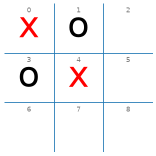


   action  total utility  # of playouts      UCB1
0       2             22             24  1.536154
1       5              9             13  1.534025
2       6             14             18  1.493100
3       7              9             13  1.534025
4       8             32             32  1.536492

Best action: 8
8.62 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

### o is about to win

Board:


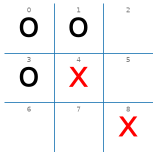


   action  total utility  # of playouts      UCB1
0       2             42            536  0.238905
1       5            -11             13  0.184735
2       6             23            431  0.232402
3       7            -12             20  0.231129

Best action: 2
54.8 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### x can draw if it chooses 7

Board:


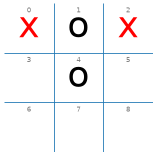


   action  total utility  # of playouts      UCB1
0       3            -11             33  0.313700
1       5             -9             65  0.322566
2       6            -11             21  0.287289
3       7            170            859  0.324724
4       8            -11             22  0.292450

Best action: 7
115 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### Empty board: Only a draw an be guaranteed

Board:


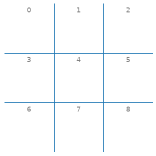


   action  total utility  # of playouts      UCB1
0       0              2             11  1.096861
1       1             -1              6  1.072307
2       2              0              8  1.072983
3       3              5             15  1.116929
4       4              1              9  1.122729
5       5              1              9  1.122729
6       6              8             19  1.117296
7       7              9             20  1.128614
8       8             -2              3  1.085507

Best action: 7
18.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


   action  total utility  # of playouts      UCB1
0       0             77            252  0.565549
1       1              6             74  0.560867
2       2            159            434  0.564475
3       3             18            109  0.560459
4       4           1874           3750  0.567131
5       5              4             68  0.559329
6       6             -8             14  0.531632
7       7             -5             37  0.543384
8       8             81            262  0.564144

Best action: 4
798 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

### A bad situation

Board:


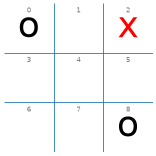


   action  total utility  # of playouts      UCB1
0       1             -6             10  0.359705
1       3             -5              5  0.357228
2       4              6             64  0.473107
3       5             -6              8  0.322983
4       6             -5              5  0.357228
5       7             -6              8  0.322983

Best action: 4


4

In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [12]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 92, 'o': 6, 'd': 2}

369 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 18, 'o': 69, 'd': 13}

300 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [13]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 95, 'o': 1, 'd': 4}

3.33 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 5, 'o': 84, 'd': 11}

2.66 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [14]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 93, 'o': 2, 'd': 5}

3.56 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 29, 'o': 47, 'd': 24}

3.09 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


# Bổ sung Bài 6 - Monte Carlo Tree Search với UCB1

Các thí nghiệm dưới đây dùng lại `playout`, `UCT_depth1`, `ucb1_10_player` và `ucb1_100_player` ở các ô phía trên;
các ô gốc giữ nguyên. Mọi thí nghiệm đặt `DEBUG = 0` và cố định seed NumPy ở đầu thí nghiệm để chạy lại cho cùng kết
quả. Phần so sánh với Pure Monte Carlo Search (Bài 5) sẽ bổ sung ở ngày 2, khi có số liệu của #27.

## 1. Cách `UCT_depth1` hoạt động và công thức UCB1

`UCT_depth1` là UCT bị giới hạn ở cây sâu 1: gốc là bàn hiện tại, mỗi nút con là một nước đi hợp lệ $a_i$. Với mỗi
nước, thuật toán lưu tổng lợi ích $u_i$ (theo góc nhìn bên đang tìm nước: thắng $+1$, hòa $0$, thua $-1$) và số playout
$n_i$; $n$ là tổng số playout đã chạy. Mỗi vòng trong $N$ vòng gồm:

1. Select: chọn nước có UCB1 lớn nhất,
   $$\mathrm{UCB1}_i = \underbrace{\frac{u_i}{n_i}}_{\text{khai thác}} + \underbrace{C\sqrt{\frac{\ln n}{n_i}}}_{\text{khám phá}}, \qquad C = \sqrt{2}.$$
   Nước chưa thử có UCB1 $= +\infty$ nên mọi nước được thử ít nhất một lần trước.
2. Expand: bỏ qua, cây luôn giữ độ sâu 1.
3. Simulate: `playout` đi nước $a_i$, sau đó hai bên đi ngẫu nhiên tới hết ván và trả lợi ích của ván.
4. Back-propagate: cộng kết quả vào $u_i$, tăng $n_i$ và $n$, rồi tính lại UCB1 của mọi nước đã thử.

Hết $N$ playout, thuật toán trả nước có nhiều playout nhất chứ không phải nước có trung bình cao nhất: UCB1 dồn
playout vào nước tốt, nên số playout là thước đo ổn định hơn trung bình của một nước mới thử vài lần.

- Khai thác: số hạng đầu là lợi ích trung bình, ưu tiên nước đang cho kết quả tốt.
- Khám phá: số hạng sau lớn khi $n_i$ nhỏ so với $n$ và tăng chậm theo $\ln n$, nên nước bị bỏ quên lâu sẽ được
  thử lại; $C$ điều chỉnh mức cân bằng giữa hai số hạng.
- Giới hạn: playout ngẫu nhiên cho cả hai bên, nên giá trị ước lượng là kết quả kỳ vọng khi hai bên chơi ngẫu nhiên,
  không phải khi đối thủ chơi tối ưu.

Ô dưới chạy `UCT_depth1` gốc trên thế "x can draw if it chooses 7" với $N = 1000$ và ghi lại từng playout bằng cách bọc
tạm hàm `playout` (không chép lại thuật toán), rồi tách UCB1 cuối cùng của mỗi nước thành hai số hạng.

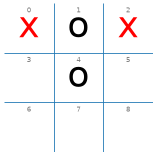

,Số playout,Tổng lợi ích,Khai thác (u/n),Khám phá,UCB1,Tỷ lệ playout (%)
Nước,,,,,,
3,89,-10,-0.112,0.394,0.282,8.9
5,95,-10,-0.105,0.381,0.276,9.5
6,47,-12,-0.255,0.542,0.287,4.7
7,730,117,0.160,0.138,0.298,73.0
8,39,-12,-0.308,0.595,0.287,3.9


Nước được chọn: 7


In [15]:
import math
from collections import Counter
from time import perf_counter

import matplotlib.pyplot as plt

DEBUG = 0
original_playout = playout

def trace_ucb1(board, N, player='x'):
    # Chạy UCT_depth1 gốc; ghi (nước, lợi ích) của từng playout bằng cách bọc tạm hàm playout toàn cục.
    global playout
    log = []

    def recording_playout(state, action, player='x'):
        value = original_playout(state, action, player=player)
        log.append((action, value))
        return value

    playout = recording_playout
    try:
        chosen = UCT_depth1(board, N=N, player=player)
    finally:
        playout = original_playout
    return chosen, pd.DataFrame(log, columns=['Nước', 'Lợi ích'])

def ucb1_breakdown(log, C=math.sqrt(2)):
    n = len(log)
    table = log.groupby('Nước')['Lợi ích'].agg(['count', 'sum']).rename(columns={'count': 'Số playout', 'sum': 'Tổng lợi ích'})
    table['Khai thác (u/n)'] = table['Tổng lợi ích'] / table['Số playout']
    table['Khám phá'] = C * (math.log(n) / table['Số playout']) ** 0.5
    table['UCB1'] = table['Khai thác (u/n)'] + table['Khám phá']
    table['Tỷ lệ playout (%)'] = 100 * table['Số playout'] / n
    return table.round(3)

draw_board = empty_board()
draw_board[0], draw_board[1], draw_board[2], draw_board[4] = 'x', 'o', 'x', 'o'
np.random.seed(0)
chosen, draw_log = trace_ucb1(draw_board, N=1000)
show_board(draw_board)
display(ucb1_breakdown(draw_log))
print('Nước được chọn:', chosen)

**Nhận xét.** Sau 1000 playout, nước 7 (nước duy nhất giữ hòa) nhận 730 playout (73%), mỗi nước còn lại chỉ nhận 39-95
playout. Khi kết thúc, UCB1 của 5 nước gần bằng nhau (0,276-0,298): nước 7 có số hạng khai thác cao nhất (0,160) nhưng
số hạng khám phá nhỏ nhất (0,138) vì đã được thử nhiều; các nước thua có khai thác âm nhưng khám phá lớn (0,381-0,595).
Đây là trạng thái cân bằng mà UCB1 hướng tới: nước nào có UCB1 cao hơn thì được thử tiếp cho tới khi các giá trị xấp xỉ
nhau, nên phần lớn ngân sách rơi vào nước tốt, còn các nước kém vẫn được thử đủ để không bị loại nhầm. Trung bình của
nước 7 là +0,160 chứ không phải 0 vì o đi ngẫu nhiên trong playout nên x đôi khi vẫn thắng.

## 2. `ucb1_10_player`, `ucb1_100_player` trên các trạng thái test

Thiết kế: dùng lại 5 thế cờ ở mục "Some Tests" (x đến lượt). Mỗi thế chạy `ucb1_10_player`, `ucb1_100_player` và
`UCT_depth1` với $N = 1000$, mỗi cấu hình 50 lần (seed 0). Đáp án được tính bằng Minimax duyệt hết cây (hàm
`exact_value` dưới đây chỉ dùng để chấm, không phải tác tử):

- Nước tối ưu (Minimax): các nước có giá trị Minimax lớn nhất.
- Nước mong đợi: thắng ngay nếu có, nếu không thì chặn đe dọa thắng ngay của o; bàn trống không có nước mong đợi
  riêng vì mọi nước đều hòa.

Kỳ vọng: $N = 10$ chọn dao động nhiều; tăng $N$ thì tỷ lệ chọn nước mong đợi tăng và số nước khác nhau giảm;
thời gian mỗi lần gọi tăng gần tuyến tính theo $N$.

In [16]:
from functools import lru_cache

@lru_cache(maxsize=None)
def exact_value(board, to_move, me):
    # Giá trị Minimax chính xác theo góc nhìn `me` (duyệt hết cây); chỉ dùng để chấm đáp án.
    board = list(board)
    value = utility(board, me)
    if value is not None:
        return value
    values = [exact_value(tuple(result(board, to_move, a)), other(to_move), me) for a in actions(board)]
    return max(values) if to_move == me else min(values)

def minimax_move_values(board, player='x'):
    return {a: exact_value(tuple(result(board, player, a)), other(player), player) for a in actions(board)}

def make_board(x=(), o=()):
    board = empty_board()
    for i in x:
        board[i] = 'x'
    for i in o:
        board[i] = 'o'
    return board

TEST_BOARDS = {
    'x sắp thắng': (make_board(x=(0, 4), o=(1, 3)), {8}),
    'o sắp thắng': (make_board(x=(4, 8), o=(0, 1, 3)), {2, 6}),
    'x hòa nếu chọn 7': (make_board(x=(0, 2), o=(1, 4)), {7}),
    'bàn trống': (empty_board(), None),
    'thế xấu': (make_board(x=(2,), o=(0, 8)), {4}),
}
PLAYERS = {10: ucb1_10_player, 100: ucb1_100_player,
           1000: lambda board, player='x': UCT_depth1(board, N=1000, player=player)}
RUNS = 50

DEBUG = 0
rows = []
for name, (board, expected) in TEST_BOARDS.items():
    values = minimax_move_values(board)
    best = max(values.values())
    optimal = {a for a, v in values.items() if v == best}
    for N, agent in PLAYERS.items():
        np.random.seed(0)
        start = perf_counter()
        picks = [agent(board, 'x') for _ in range(RUNS)]
        elapsed = (perf_counter() - start) / RUNS
        counts = Counter(picks)
        rows.append({'Thế cờ': name, 'N': N,
                     'Giá trị Minimax tốt nhất': best, 'Nước tối ưu': sorted(optimal),
                     '% chọn nước tối ưu': 100 * sum(counts[a] for a in optimal) / RUNS,
                     'Nước mong đợi': sorted(expected) if expected else 'mọi nước',
                     '% chọn nước mong đợi': 100 * sum(counts[a] for a in expected) / RUNS if expected else None,
                     'Số nước khác nhau': len(counts),
                     'Nước chọn nhiều nhất': counts.most_common(1)[0][0],
                     'Thời gian TB/lần (ms)': round(1000 * elapsed, 2)})
test_results = pd.DataFrame(rows)
for name, (board, _) in TEST_BOARDS.items():
    print(name, '- giá trị Minimax của từng nước:', minimax_move_values(board))
display(test_results)

x sắp thắng - giá trị Minimax của từng nước: {2: 1, 5: 0, 6: 1, 7: 0, 8: 1}
o sắp thắng - giá trị Minimax của từng nước: {2: -1, 5: -1, 6: -1, 7: -1}
x hòa nếu chọn 7 - giá trị Minimax của từng nước: {3: -1, 5: -1, 6: -1, 7: 0, 8: -1}
bàn trống - giá trị Minimax của từng nước: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0}
thế xấu - giá trị Minimax của từng nước: {1: -1, 3: -1, 4: -1, 5: -1, 6: -1, 7: -1}


,Thế cờ,N,Giá trị Minimax tốt nhất,Nước tối ưu,% chọn nước tối ưu,Nước mong đợi,% chọn nước mong đợi,Số nước khác nhau,Nước chọn nhiều nhất,Thời gian TB/lần (ms)
0,x sắp thắng,10,1,"[2, 6, 8]",82.0,[8],4.0,5,2,0.69
1,x sắp thắng,100,1,"[2, 6, 8]",100.0,[8],96.0,2,8,5.93
2,x sắp thắng,1000,1,"[2, 6, 8]",100.0,[8],100.0,1,8,39.37
3,o sắp thắng,10,-1,"[2, 5, 6, 7]",100.0,"[2, 6]",88.0,4,2,0.46
4,o sắp thắng,100,-1,"[2, 5, 6, 7]",100.0,"[2, 6]",100.0,2,6,4.82
5,o sắp thắng,1000,-1,"[2, 5, 6, 7]",100.0,"[2, 6]",100.0,2,6,49.24
6,x hòa nếu chọn 7,10,0,[7],34.0,[7],34.0,5,7,0.80
7,x hòa nếu chọn 7,100,0,[7],84.0,[7],84.0,3,7,8.17
8,x hòa nếu chọn 7,1000,0,[7],100.0,[7],100.0,1,7,89.79
9,bàn trống,10,0,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",100.0,mọi nước,NaN,6,0,1.59


**Nhận xét.**
- N = 10 dao động mạnh: ở "x sắp thắng" và "x hòa nếu chọn 7", 50 lần chạy cho 5 nước khác nhau; chỉ 4% chọn nước
  thắng ngay 8 và 34% chọn nước giữ hòa 7. Với 5 nước và 10 playout, mỗi nước chỉ được thử khoảng 2 lần, số playout của
  các nước thường bằng nhau và `n.index(max(n))` trả nước có chỉ số nhỏ nhất, nên kết quả nghiêng về nước đầu danh sách
  (nước 2 được chọn nhiều nhất ở "x sắp thắng"). Nước 2 vẫn thắng nếu x chơi đúng tiếp, nên tỷ lệ chọn nước tối ưu là 82%.
- Tăng N thì ổn định hơn: tỷ lệ chọn nước mong đợi tăng lên 84-100% ở N = 100 và 100% ở N = 1000 trên cả 4 thế có
  nước mong đợi; số nước khác nhau giảm còn 1 (riêng "o sắp thắng" còn 2 vì cả 2 và 6 đều là nước chặn).
- "o sắp thắng" và "thế xấu": theo Minimax, mọi nước của x đều thua, nên tỷ lệ chọn nước tối ưu luôn là 100% và không
  có ý nghĩa. UCB1 vẫn chọn nước chặn (4 ở "thế xấu") vì nó ước lượng kết quả khi o đi ngẫu nhiên; o ngẫu nhiên hiếm khi
  khai thác được bẫy, đúng như ghi chú của đề.
- Bàn trống: mọi nước đều hòa theo Minimax; ở N = 1000, lựa chọn dồn vào 3 nước và ô giữa (4) được chọn nhiều nhất,
  vì khi hai bên chơi ngẫu nhiên thì đi ô giữa có tỷ lệ thắng cao nhất.
- Thời gian tăng gần tuyến tính theo N: theo cột thời gian, mỗi lần gọi mất khoảng 0,5-1,6 ms ở N = 10, 5-16 ms ở
  N = 100 và 39-158 ms ở N = 1000, tức N tăng 10 lần thì thời gian tăng khoảng 10 lần; bàn trống chậm nhất vì playout
  dài nhất.

## 3. Đấu với `random_player`

Thiết kế: dùng hàm `play` gốc, mỗi cặp 100 ván. UCB1 với $N = 10$ và $N = 100$ lần lượt đi trước (x) và đi sau (o);
thêm cặp random đấu random làm mốc. Seed 42 ở đầu mỗi cặp. Thời gian trung bình mỗi nước chỉ tính thời gian của tác
tử UCB1, đo bằng cách bọc hàm tác tử.

Kỳ vọng: UCB1 thắng phần lớn số ván, $N = 100$ thắng nhiều và thua ít hơn $N = 10$; đi trước có lợi hơn đi sau;
thời gian mỗi nước của $N = 100$ khoảng gấp 10 lần $N = 10$.

In [17]:
def timed(agent):
    # Bọc tác tử để ghi thời gian của từng lần chọn nước.
    times = []

    def wrapper(board, player='x'):
        start = perf_counter()
        action = agent(board, player)
        times.append(perf_counter() - start)
        return action

    return wrapper, times

DEBUG = 0
np.random.seed(42)
baseline = play(random_player, random_player)
rows = [{'Tác tử': 'random', 'Lượt': 'đi trước (x)', 'Số ván': sum(baseline.values()), 'Thắng': baseline['x'],
         'Hòa': baseline['d'], 'Thua': baseline['o'], 'Số nước của tác tử': None, 'Thời gian TB/nước (ms)': None}]
for label, agent in (('UCB1 (N=10)', ucb1_10_player), ('UCB1 (N=100)', ucb1_100_player)):
    for first in (True, False):
        np.random.seed(42)
        player, times = timed(agent)
        outcome = play(player, random_player) if first else play(random_player, player)
        me, opponent = ('x', 'o') if first else ('o', 'x')
        rows.append({'Tác tử': label, 'Lượt': 'đi trước (x)' if first else 'đi sau (o)',
                     'Số ván': sum(outcome.values()), 'Thắng': outcome[me], 'Hòa': outcome['d'],
                     'Thua': outcome[opponent], 'Số nước của tác tử': len(times),
                     'Thời gian TB/nước (ms)': round(1000 * np.mean(times), 3)})
versus_random = pd.DataFrame(rows)
display(versus_random)

,Tác tử,Lượt,Số ván,Thắng,Hòa,Thua,Số nước của tác tử,Thời gian TB/nước (ms)
0,random,đi trước (x),100,58,17,25,NaN,NaN
1,UCB1 (N=10),đi trước (x),100,94,2,4,362.0,0.965
2,UCB1 (N=10),đi sau (o),100,76,6,18,328.0,0.820
3,UCB1 (N=100),đi trước (x),100,98,2,0,342.0,9.611
4,UCB1 (N=100),đi sau (o),100,82,9,9,322.0,8.100


**Nhận xét.**
- Mốc random đấu random: bên đi trước thắng 58, hòa 17, thua 25 ván, tức đi trước đã có lợi sẵn.
- UCB1 đi trước: N = 10 thắng 94, hòa 2, thua 4; N = 100 thắng 98, hòa 2 và không thua ván nào.
- UCB1 đi sau: N = 10 thắng 76, thua 18; N = 100 thắng 82, thua 9. Đi sau khó hơn, nhưng tăng N vẫn giảm số ván thua
  một nửa.
- Thời gian mỗi nước: khoảng 0,8-1 ms ở N = 10 và khoảng 8-10 ms ở N = 100 (cột cuối của bảng), tức khoảng gấp 10
  lần, đúng như thời gian tỷ lệ với số playout.
- Số liệu cho bảng tổng hợp chung (100 ván, tác tử đi trước): UCB1 N = 10 là 94 / 2 / 4 ván; UCB1 N = 100 là 98 / 2 / 0
  ván; thời gian mỗi nước lấy ở cột cuối của bảng trên.

## 4. Phân bổ mô phỏng của UCB1 so với chia đều

Thiết kế: với cùng ngân sách $N = 1000$ playout, chia đều nghĩa là mỗi nước nhận $N/k$ playout ($k$ là số nước
hợp lệ). Ghi lại từng playout của `UCT_depth1` gốc (bọc `playout` như mục 1) trên hai thế: "x hòa nếu chọn 7" (một
nước giữ hòa, các nước khác thua) và "x sắp thắng" (nước 8 thắng ngay). Vẽ số playout mỗi nước so với mức chia đều, và
tỷ lệ playout dồn vào nước mong đợi theo tiến trình.

Kỳ vọng: UCB1 dồn phần lớn playout vào nước mong đợi, các nước kém chỉ nhận đủ playout để loại trừ; tỷ lệ dồn vào
nước tốt tăng dần theo số playout.

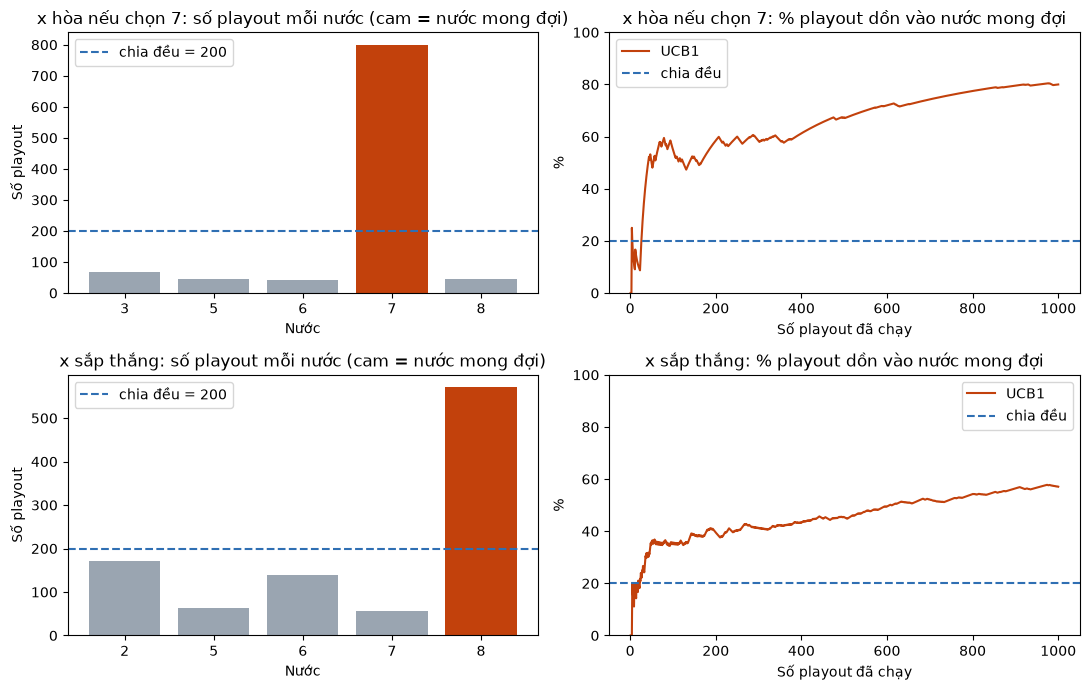

,Thế cờ,Số nước,Chia đều (playout/nước),UCB1: playout cho nước mong đợi,UCB1: playout ít nhất cho một nước,Nước được chọn
0,x hòa nếu chọn 7,5,200.0,800,42,7
1,x sắp thắng,5,200.0,571,57,8


In [18]:
N_ALLOC = 1000
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
alloc_rows = []
for row, name in enumerate(('x hòa nếu chọn 7', 'x sắp thắng')):
    board, expected = TEST_BOARDS[name]
    np.random.seed(1)
    chosen, log = trace_ucb1(board, N=N_ALLOC)
    counts = log['Nước'].value_counts().reindex(actions(board), fill_value=0)
    uniform = N_ALLOC / len(counts)
    colors = ['#c2410c' if a in expected else '#9aa5b1' for a in counts.index]
    axes[row, 0].bar([str(a) for a in counts.index], counts.values, color=colors)
    axes[row, 0].axhline(uniform, color='#2f6fb3', linestyle='--', label=f'chia đều = {uniform:.0f}')
    axes[row, 0].set_title(f'{name}: số playout mỗi nước (cam = nước mong đợi)')
    axes[row, 0].set_xlabel('Nước')
    axes[row, 0].set_ylabel('Số playout')
    axes[row, 0].legend()
    share = log['Nước'].isin(expected).cumsum() / np.arange(1, len(log) + 1)
    axes[row, 1].plot(np.arange(1, len(log) + 1), 100 * share, color='#c2410c', label='UCB1')
    axes[row, 1].axhline(100 * len(expected) / len(counts), color='#2f6fb3', linestyle='--', label='chia đều')
    axes[row, 1].set_title(f'{name}: % playout dồn vào nước mong đợi')
    axes[row, 1].set_xlabel('Số playout đã chạy')
    axes[row, 1].set_ylabel('%')
    axes[row, 1].set_ylim(0, 100)
    axes[row, 1].legend()
    alloc_rows.append({'Thế cờ': name, 'Số nước': len(counts), 'Chia đều (playout/nước)': round(uniform, 1),
                       'UCB1: playout cho nước mong đợi': int(counts[list(expected)].sum()),
                       'UCB1: playout ít nhất cho một nước': int(counts.min()),
                       'Nước được chọn': chosen})
plt.tight_layout()
plt.show()
display(pd.DataFrame(alloc_rows))

**Nhận xét.** Với cùng 1000 playout, chia đều cho 5 nước thì mỗi nước nhận 200 playout. UCB1 dồn 800 playout (80%) vào
nước 7 ở "x hòa nếu chọn 7" và 571 playout vào nước 8 ở "x sắp thắng", trong khi nước kém nhất vẫn nhận 42 và 57 playout.
Đường tỷ lệ cho thấy ở đầu quá trình UCB1 gần như chia đều (mỗi nước phải được thử trước), sau đó tỷ lệ dồn vào nước mong
đợi tăng dần khi trung bình của các nước tách nhau ra.

## 5. Trả lời câu hỏi

UCB1 cân bằng exploration và exploitation thế nào? 

Mỗi nước được chấm bằng tổng của hai số hạng: trung bình lợi ích
$u_i/n_i$ (khai thác, ưu tiên nước đang tốt) và $C\sqrt{\ln n / n_i}$ (khám phá, lớn khi nước ít được thử). Khi một nước
được thử thêm, số hạng khám phá của nó giảm, còn số hạng khám phá của các nước khác tăng chậm theo $\ln n$. Vì vậy thuật
toán thử nước tốt nhiều nhất nhưng thỉnh thoảng quay lại nước ít được thử để kiểm tra lại. Mục 1 cho thấy trạng thái
cân bằng này: khi kết thúc, UCB1 của mọi nước xấp xỉ nhau, trong đó nước 7 nhận 73% playout. Nước chưa thử có UCB1 vô
cực nên mọi nước đều được thử ít nhất một lần.

Tăng số mô phỏng thì có ổn định hơn không? 

Có. Ở mục 2, tỷ lệ chọn nước mong đợi tăng từ 4-88% (N = 10) lên 84-100%
(N = 100) và 100% (N = 1000); trên các thế có nước mong đợi, số nước khác nhau giữa 50 lần chạy giảm từ 4-6 xuống 1-2. Ở mục 3, N = 100 thua ít hơn
N = 10 ở cả hai lượt đi. Cái giá là thời gian tăng gần tuyến tính theo N. Ổn định hơn không có nghĩa là tối ưu hơn trước
đối thủ giỏi: playout ngẫu nhiên khiến UCB1 ước lượng kết quả khi đối thủ chơi ngẫu nhiên (ví dụ "thế xấu"). Khi N gần
bằng số nước (N = 10 với 5 nước), UCB1 gần như chỉ thử mỗi nước một hai lần và kết quả phụ thuộc cách phá hòa.

Câu thảo luận 5. UCB1 cải thiện phân bổ mô phỏng so với chia đều thế nào? 

Chia đều tiêu cùng $N/k$ playout cho mọi
nước, kể cả nước đã rõ là kém. UCB1 phân bổ thích nghi: sau vài playout đầu, nước có trung bình thấp chỉ được thử thêm
khi số hạng khám phá đủ lớn, nên số playout của nó chỉ tăng theo bậc $\ln N$; phần ngân sách tiết kiệm được dồn vào nước
tốt. Ở mục 4, nước 7 nhận 800/1000 playout thay vì 200, nên ước lượng cho nước sẽ được chọn chính xác hơn với cùng ngân
sách, đồng thời các nước kém vẫn có 42-57 playout nên ít bị loại nhầm. So sánh trực tiếp với số liệu Pure Monte Carlo
Search của Bài 5 (chia đều playout) sẽ bổ sung ở ngày 2, khi có số liệu từ #27.